# Hebron: do the method's candidates match OCHA's demolition records?

**What OCHA gives.** OCHA records every demolition it verifies in the West Bank with:
* the date;
* the **community** (a village, or for the city just "Hebron");
* the number of structures and of people displaced.

The copy used here (`demo-repository.xlsx`, from the Dryad dataset *Occupation, violence, and displacement in the West Bank*, extracted from OCHA on 15 July 2024) runs to 30 June 2024. It has no structure type and no coordinates.

**What that allows.** A record says "a demolition happened in this community around this date", not which building. So the test is about **place and time together**: near the community, does the method flag buildings with a detected date just after the OCHA date **more often than at other times**? If the candidates are unrelated to real demolitions, flags near a community are spread evenly in time, and OCHA dates fall on them only by chance.

**The steps:**
1. Read the records; keep Hebron governorate from `START`.
2. Find each community on the map. OpenStreetMap is asked once and the answer cached; you check the map and correct names with `MANUAL_COORDS`.
3. Keep the communities inside the study area (`BBOX`, as in the main notebook). Write their incidents as a list for the check by eye: in Google Earth, find the building demolished at that place and date.
4. **Once the main notebook (v7) has run:** for each incident, count the demolition candidates within `RADIUS_M` of the community whose detected date is the first acquisition after the OCHA date (± `DATE_TOL_DAYS`). Then compare with the same count for random dates, repeated `N_DRAWS` times.

**The result reads as an enrichment.** Observed hits divided by the hits expected by chance, with the probability of getting at least that many by chance. Above 1, with a small probability, means the candidates line up with real demolitions in time and place.

**What to expect, honestly:**
* **Most OCHA structures are not buildings the radar can see.** The dashboard's breakdown for Hebron governorate (Area C, 2020–2026): agriculture 547, water and sanitation 273, livelihood 181, infrastructure 48, other 60, residential 436 of 1,545. Tents, cisterns and animal shelters are too small or too flat for a 20 m radar, and are mostly not in the building outlines.
* **Many communities lie outside the study area,** notably Masafer Yatta to the south.
* **"Hebron" means the whole city.** A point for it says nothing about where in the city, so it is left out of the test (`SKIP_COMMUNITIES`).
* **This copy misses some records:** about 640 structures in 2020 to mid-2024, against about 950 on the dashboard for Area C alone.

So a modest match is the most this test can show. Its value is that it compares against chance, and that it hands your colleagues a list of places and dates to find the real buildings: the building-level references that settle the question.

In [3]:
!pip install openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [openpyxl]


In [4]:
import json
import time
import urllib.parse
import urllib.request
from datetime import date
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from shapely.geometry import Point, box

import hebron_tools as ht

# ── Settings ─────────────────────────────────────────────────────────────────
DATA = Path("/run/media/samuel-appiah-kubi/New Volume/hebronv5")
RESULTS = DATA / "results"
OCHA_FILES = [DATA / "references" / "demo-repository.xlsx"]   # put the Dryad file here; more files with the same columns can be added
BBOX = (35.04, 31.48, 35.18, 31.60)            # the main notebook's study area (min_lon, min_lat, max_lon, max_lat)
GOVERNORATE = "Hebron"
START = "2020-01-01"
CANDIDATES = RESULTS / "hebron_candidates_v6.gpkg"           # written by section 8 of the main notebook (v7)
INVENTORY = RESULTS / "grd_inventory.json"                   # the acquisition dates of the main notebook
TRACK_KEY = "D094"
TEST = ht.TestParams(ref_days=365, post_days=150, confirm_days=365, min_ref=4, min_post=2, min_confirm=2, season_check=False)
RADIUS_M = 1000          # candidates within this distance of a community's point count for it
DATE_TOL_DAYS = 15       # a candidate's date may differ this much from the first acquisition after the OCHA date (one acquisition)
N_DRAWS = 2000           # random-date repetitions for the chance level
SKIP_COMMUNITIES = ["Hebron", "Massafer Yatta", "Masafer Bani Na'im"]   # names that cover a whole city or region
MANUAL_COORDS = {}       # community name -> (lon, lat), to correct or add a location by hand
GEOCODE_CACHE = RESULTS / "ocha_communities.csv"
OUT = RESULTS / "ocha_check"
OUT.mkdir(parents=True, exist_ok=True)

## 1. The records

In [5]:
frames = []
for f in OCHA_FILES:
    t = pd.read_excel(f) if str(f).lower().endswith((".xlsx", ".xls")) else pd.read_csv(f)
    t = t.rename(columns={"Dateofincident": "date", "community_name": "community", "TotalNumberofStructures": "structures",
                          "NumberofDisplacedPeople": "displaced", "GeneralLocation": "area"})
    frames.append(t.assign(source=Path(f).name))
OCHA = pd.concat(frames, ignore_index=True)
OCHA["date"] = pd.to_datetime(OCHA["date"])
OCHA = OCHA[(OCHA["Governorate"] == GOVERNORATE) & (OCHA["date"] >= START)].drop_duplicates(["date", "community", "structures"])
OCHA["community"] = OCHA["community"].astype(str).str.strip()
print(f"{len(OCHA)} incidents, {OCHA['structures'].sum()} structures, {OCHA['date'].min():%Y-%m-%d} .. {OCHA['date'].max():%Y-%m-%d}, "
      f"{OCHA['community'].nunique()} communities")
display(OCHA.groupby(OCHA["date"].dt.year).agg(incidents=("community", "size"), structures=("structures", "sum")))

239 incidents, 636 structures, 2020-01-08 .. 2024-06-26, 68 communities


,incidents,structures
date,,
2020,58,142
2021,38,101
2022,64,148
2023,49,159
2024,30,86


## 2. Where the communities are

Each name is looked up once in OpenStreetMap (Nominatim, one request a second, restricted to the area around Hebron), and the answers are cached in `results/ocha_communities.csv`. Spellings differ between OCHA and OpenStreetMap, so check the table and the map:

* **Not found:** look the community up in Google Earth and add it to `MANUAL_COORDS` as `"name": (lon, lat)`.
* **Found in the wrong place:** a different village of a similar name. Correct it the same way.

Then run this cell again.

48 of 68 communities located; 9 inside the study area


/tmp/ipykernel_39053/3549570566.py:31: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  cache = pd.concat([cache, pd.DataFrame(rows)], ignore_index=True)


,how,lon,lat,inside,incidents,structures,osm_name
community,,,,,,,
Hebron,OpenStreetMap,35.094487,31.528902,True,32,65,"الخليل, אזור H1, الضفة الغربية, 150, الأراضي ا..."
Bani Na'im,OpenStreetMap,35.163048,31.516871,True,6,17,"بني نعيم, منطقة أ, الضفة الغربية, الأراضي الفل..."
Birin,OpenStreetMap,35.136339,31.490014,True,8,15,"Birin, מועצה אזורית הר חברון, שטח C, יהודה ושו..."
Halhul,OpenStreetMap,35.099316,31.577547,True,10,15,"حلحول‎, منطقة أ, الضفة الغربية, الأراضي الفلسط..."
Al Hijra,OpenStreetMap,35.054513,31.490376,True,3,11,"الهجرة, دورا, منطقة ب, الضفة الغربية, 150, الأ..."
...,...,...,...,...,...,...,...
Dura,OpenStreetMap,35.026367,31.506598,False,1,1,"دورا, منطقة أ, الضفة الغربية, الأراضي الفلسطينية"
Shuyukh al 'Arrub,OpenStreetMap,35.155274,31.609340,False,1,1,"Orqan Trad - Shuyukh Al 'Arrub, بيت فجار, مجلس..."
Khirbet Zanuta,OpenStreetMap,34.995383,31.371349,False,1,1,"خربة زنوتة, מועצה אזורית הר חברון, שטח C, יהוד..."


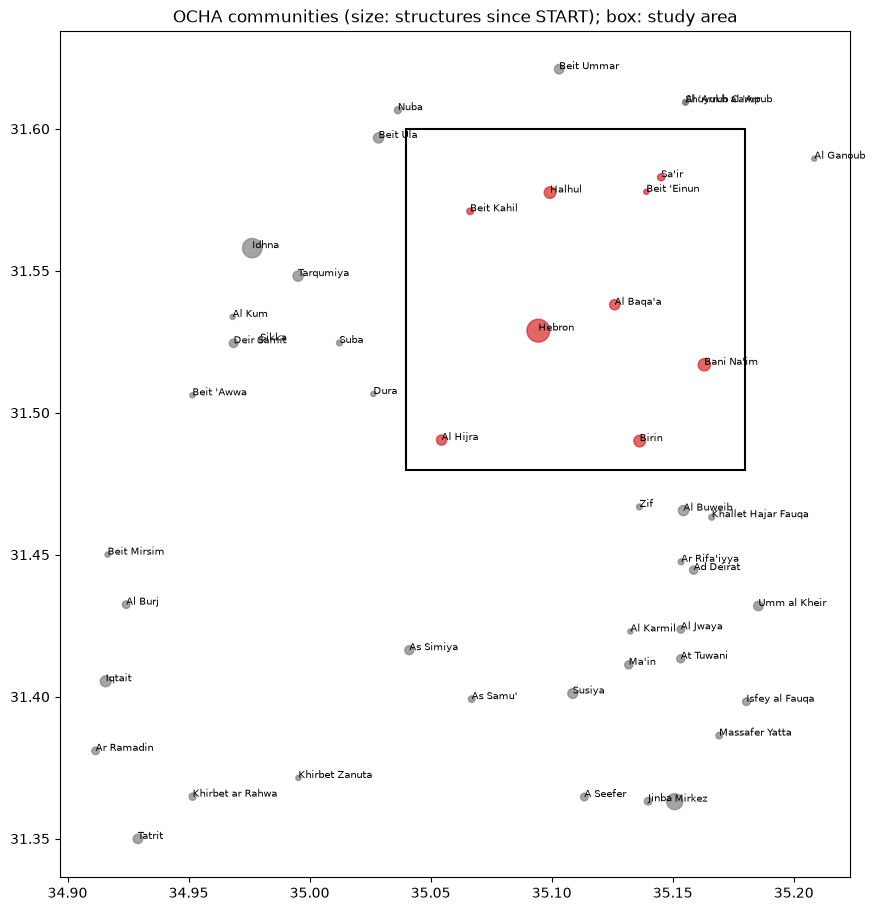

In [6]:
cache = pd.read_csv(GEOCODE_CACHE) if GEOCODE_CACHE.exists() else pd.DataFrame(columns=["community", "lon", "lat", "osm_name", "how"])
known = set(cache["community"])
todo = [c for c in OCHA["community"].unique() if c not in known and c not in MANUAL_COORDS]
VIEW = (34.85, 31.30, 35.35, 31.72)                       # Hebron governorate and a margin


def nominatim(q):
    url = "https://nominatim.openstreetmap.org/search?" + urllib.parse.urlencode(
        {"q": q, "format": "json", "limit": 1, "viewbox": ",".join(map(str, VIEW)), "bounded": 1})
    req = urllib.request.Request(url, headers={"User-Agent": "hebron-change-research/1.0 (research use)"})
    with urllib.request.urlopen(req, timeout=30) as r:
        out = json.loads(r.read().decode())
    time.sleep(1.1)                                        # Nominatim's usage policy: at most one request a second
    return out[0] if out else None


rows = []
for c in todo:
    hit = None
    for q in (c, c.replace("Khirbet ", "Khirbat "), c.replace("Al ", "Al-").replace("Ar ", "Ar-").replace("As ", "As-")):
        try:
            hit = nominatim(q)
        except Exception as exc:
            print(f"lookup failed for {c!r}: {exc}")
            break
        if hit:
            break
    rows.append({"community": c, "lon": float(hit["lon"]) if hit else np.nan, "lat": float(hit["lat"]) if hit else np.nan,
                 "osm_name": hit["display_name"][:80] if hit else "", "how": "OpenStreetMap" if hit else "not found"})
if rows:
    cache = pd.concat([cache, pd.DataFrame(rows)], ignore_index=True)
    cache.to_csv(GEOCODE_CACHE, index=False)
COMM = cache.set_index("community")
for c, (lon, lat) in MANUAL_COORDS.items():
    COMM.loc[c, ["lon", "lat", "osm_name", "how"]] = [lon, lat, "", "by hand"]
COMM = COMM.loc[COMM.index.isin(OCHA["community"].unique())].copy()
COMM["inside"] = COMM["lon"].between(BBOX[0], BBOX[2]) & COMM["lat"].between(BBOX[1], BBOX[3])
COMM = COMM.join(OCHA.groupby("community").agg(incidents=("date", "size"), structures=("structures", "sum")))
print(f"{int(COMM['lon'].notna().sum())} of {len(COMM)} communities located; {int(COMM['inside'].sum())} inside the study area")
display(COMM.sort_values(["inside", "structures"], ascending=False)[["how", "lon", "lat", "inside", "incidents", "structures", "osm_name"]])

fig, ax = plt.subplots(figsize=(9, 9), constrained_layout=True)
ax.add_patch(plt.Rectangle((BBOX[0], BBOX[1]), BBOX[2] - BBOX[0], BBOX[3] - BBOX[1], fill=False, color="k", lw=1.5))
ok = COMM["lon"].notna()
ax.scatter(COMM.loc[ok, "lon"], COMM.loc[ok, "lat"], s=10 + 4 * COMM.loc[ok, "structures"], c=np.where(COMM.loc[ok, "inside"], "tab:red", "tab:gray"), alpha=0.7)
for c, r in COMM[ok].iterrows():
    ax.annotate(c, (r["lon"], r["lat"]), fontsize=7)
ax.set_aspect(1 / np.cos(np.radians(31.5))); ax.set_title("OCHA communities (size: structures since START); box: study area")
plt.show()

## 3. Incidents inside the study area: a list for the check by eye

These are the incidents your colleagues can turn into building-level references:
1. Go to the community in Google Earth Pro, at the date.
2. Find the building that was standing before and is gone after, and mark it: a point, and its date.

`ocha_incidents_inside.csv` and `.kml` hold one entry per incident.

Incidents recorded only as "Hebron" (the whole city, H2 included) are listed in `ocha_incidents_whole_city.csv`. They are left out of the test, because their place in the city is unknown. They are still worth looking for by eye: they are the demolitions inside the city, where most of the study area's buildings are, and news reports of the same date usually name the neighbourhood.

In [7]:
INC = OCHA.merge(COMM[["lon", "lat", "inside"]], left_on="community", right_index=True, how="left")
INC["skipped"] = INC["community"].isin(SKIP_COMMUNITIES)
inside = INC[INC["inside"].fillna(False).astype(bool) & ~INC["skipped"]].sort_values("date").reset_index(drop=True)
inside.insert(0, "id", [f"O{i + 1:03d}" for i in range(len(inside))])
print(f"inside the study area: {len(inside)} incidents, {inside['structures'].sum()} structures, in {inside['community'].nunique()} communities;"
      f" plus {int((INC['skipped'] & INC['inside'].fillna(False).astype(bool)).sum())} for whole-city names (not placed)")
display(inside.groupby("community").agg(incidents=("date", "size"), structures=("structures", "sum"), first=("date", "min"), last=("date", "max")))
inside.assign(date=inside["date"].dt.strftime("%Y-%m-%d")).to_csv(OUT / "ocha_incidents_inside.csv", index=False)
marks = "".join(f"<Placemark><name>{r.id} {r.community}</name><description>{r.date:%Y-%m-%d}: {r.structures} structure(s), "
                f"{r.displaced} displaced</description><Point><coordinates>{r.lon:.6f},{r.lat:.6f},0</coordinates></Point></Placemark>"
                for r in inside.itertuples())
(OUT / "ocha_incidents_inside.kml").write_text('<?xml version="1.0" encoding="UTF-8"?><kml xmlns="http://www.opengis.net/kml/2.2">'
                                               f"<Document><name>OCHA incidents, Hebron study area</name>{marks}</Document></kml>", encoding="utf-8")
city = INC[INC["skipped"]].sort_values("date")
city.assign(date=city["date"].dt.strftime("%Y-%m-%d"))[["date", "community", "structures", "displaced"]].to_csv(OUT / "ocha_incidents_whole_city.csv", index=False)
print("written:", OUT / "ocha_incidents_inside.csv", "and", OUT / "ocha_incidents_inside.kml",
      f"| incidents recorded only as a whole city or region ({len(city)}): {OUT / 'ocha_incidents_whole_city.csv'}")

inside the study area: 34 incidents, 77 structures, in 8 communities; plus 32 for whole-city names (not placed)


,incidents,structures,first,last
community,,,,
Al Baqa'a,4,11,2022-06-01,2023-07-12
Al Hijra,3,11,2020-02-06,2021-02-23
Bani Na'im,6,17,2020-11-08,2024-05-07
Beit 'Einun,1,1,2022-10-03,2022-10-03
Beit Kahil,1,3,2022-02-09,2022-02-09
Birin,8,15,2020-01-16,2023-07-18
Halhul,10,15,2020-07-20,2024-06-24
Sa'ir,1,4,2021-08-05,2021-08-05


written: /run/media/samuel-appiah-kubi/New Volume/hebronv5/results/ocha_check/ocha_incidents_inside.csv and /run/media/samuel-appiah-kubi/New Volume/hebronv5/results/ocha_check/ocha_incidents_inside.kml | incidents recorded only as a whole city or region (35): /run/media/samuel-appiah-kubi/New Volume/hebronv5/results/ocha_check/ocha_incidents_whole_city.csv


## 4. Do the candidates line up with the incidents? (after the main notebook v7 has run)

**When an incident can be seen at all.** The image series has dry-season dates only (June–October), so an incident is seen at the **first acquisition after its date**: a demolition in March shows in the next June. The test can only examine that acquisition if there is a full year of images before it (`TEST`), so incidents before the first testable date are left out. Incidents whose first acquisition has not been downloaded yet are left out too.

**A hit.** A demolition candidate within `RADIUS_M` of the community whose detected date is within `DATE_TOL_DAYS` of that first acquisition.

**The chance level.** The same count with each incident's first acquisition replaced by a random testable one, `N_DRAWS` times. Acquisitions after a long gap, such as the first of a season, are drawn more often, as a random event day would be. The enrichment is observed hits divided by the average hits by chance. The p-value is the share of random draws with at least as many hits as observed.

In [8]:
if not CANDIDATES.exists():
    print(f"no {CANDIDATES} yet: run the main notebook (v7) to the end, then this cell")
else:
    inv = json.loads(INVENTORY.read_text())
    acq = np.array(sorted(date.fromisoformat(d).toordinal() for d in inv[TRACK_KEY]["dates"]), float)
    testable = ht.split_dates(acq, TEST)
    CAND = gpd.read_file(CANDIDATES, layer="demolition_candidates").to_crs(32636)
    CAND = CAND[CAND["date"].notna()].copy()
    CAND["t"] = [date.fromisoformat(d).toordinal() for d in CAND["date"]]
    cx, cy = CAND.geometry.centroid.x.to_numpy(), CAND.geometry.centroid.y.to_numpy()
    pts = gpd.GeoSeries([Point(xy) for xy in zip(inside["lon"], inside["lat"])], crs=4326).to_crs(32636)
    near = [np.flatnonzero(np.hypot(cx - p.x, cy - p.y) <= RADIUS_M) for p in pts]
    t_inc = np.array([d.toordinal() for d in inside["date"].dt.date], float)
    first_acq = np.array([acq[acq > t].min() if (acq > t).any() else np.nan for t in t_inc])
    ok = np.isin(first_acq, testable)
    print(f"{len(inside)} incidents inside; testable (first acquisition after it has a full year before it): {int(ok.sum())}")

    def hits_for(first):
        return np.array([int((np.abs(CAND["t"].to_numpy()[nb] - f) <= DATE_TOL_DAYS).sum()) if np.isfinite(f) else 0
                         for nb, f in zip(near, first)])

    h_obs = hits_for(first_acq)
    # chance: each testable incident gets a random first acquisition instead, drawn as a random event day would map onto
    # the acquisitions (an acquisition after a long gap, e.g. the first of a season, collects more days)
    rng = np.random.default_rng(0)
    prev = np.array([acq[acq < f].max() for f in testable])
    w = (testable - prev) / (testable - prev).sum()
    ct = CAND["t"].to_numpy()
    near_ok = [near[i] for i in np.flatnonzero(ok)]
    draws = []
    for _ in range(N_DRAWS):
        f_r = rng.choice(testable, size=len(near_ok), p=w)
        draws.append([int((np.abs(ct[nb] - f) <= DATE_TOL_DAYS).sum()) for nb, f in zip(near_ok, f_r)])
    draws = np.array(draws)                                   # (N_DRAWS, testable incidents)
    obs_total, chance = int(h_obs[ok].sum()), float(draws.sum(1).mean())
    obs_inc = int((h_obs[ok] > 0).sum())
    chance_inc = float((draws > 0).sum(1).mean())
    p_total = float(np.mean(draws.sum(1) >= obs_total))
    p_inc = float(np.mean((draws > 0).sum(1) >= obs_inc))
    SUMMARY = pd.DataFrame([
        {"measure": "candidates near an incident at the right time", "observed": obs_total, "by chance (mean)": round(chance, 1),
         "enrichment": round(obs_total / chance, 2) if chance else None, "p (chance >= observed)": round(p_total, 4)},
        {"measure": "incidents with at least one such candidate", "observed": obs_inc, "by chance (mean)": round(chance_inc, 1),
         "enrichment": round(obs_inc / chance_inc, 2) if chance_inc else None, "p (chance >= observed)": round(p_inc, 4)}])
    display(SUMMARY)

    inside["first_acquisition"] = [date.fromordinal(int(f)).isoformat() if np.isfinite(f) else None for f in first_acq]
    inside["testable"] = ok
    inside["candidates_near_in_time"] = h_obs
    inside["candidates_near_any_time"] = [len(nb) for nb in near]
    display(inside.loc[ok, ["id", "date", "community", "structures", "first_acquisition", "candidates_near_in_time", "candidates_near_any_time"]])
    by_year = inside[ok].groupby(inside.loc[ok, "date"].dt.year).agg(incidents=("id", "size"),
                                                                      with_candidate=("candidates_near_in_time", lambda s: int((s > 0).sum())))
    display(by_year)

    # leads for the check by eye: the candidates that matched an incident, with their outlines
    lead_rows = []
    for i in np.flatnonzero(ok & (h_obs > 0)):
        nb = near[i][np.abs(CAND["t"].to_numpy()[near[i]] - first_acq[i]) <= DATE_TOL_DAYS]
        for j in nb:
            lead_rows.append({"incident": inside.loc[i, "id"], "community": inside.loc[i, "community"],
                              "ocha_date": inside.loc[i, "date"].strftime("%Y-%m-%d"), "candidate_date": CAND.iloc[j]["date"],
                              "score": round(float(CAND.iloc[j]["score"]), 2), "geometry": CAND.geometry.iloc[j]})
    if lead_rows:
        LEADS = gpd.GeoDataFrame(lead_rows, crs=32636)
        cen = LEADS.geometry.centroid.to_crs(4326)
        LEADS = LEADS.to_crs(4326)
        LEADS.to_file(OUT / "ocha_matched_candidates.gpkg", driver="GPKG")
        LEADS.drop(columns="geometry").assign(lon=cen.x.round(6), lat=cen.y.round(6)).to_csv(OUT / "ocha_matched_candidates.csv", index=False)
        print(f"{len(LEADS)} candidate buildings matched an incident: {OUT / 'ocha_matched_candidates.csv'} (check them on imagery first)")
    inside.assign(date=inside["date"].dt.strftime("%Y-%m-%d")).to_csv(OUT / "ocha_incidents_inside.csv", index=False)
    print("SEND THESE NUMBERS:", {"incidents_inside": len(inside), "testable": int(ok.sum()),
                                  "summary": SUMMARY.to_dict("records"), "by_year": by_year.reset_index().to_dict("records")})

no /run/media/samuel-appiah-kubi/New Volume/hebronv5/results/hebron_candidates_v6.gpkg yet: run the main notebook (v7) to the end, then this cell


## Reading the result

* **Enrichment well above 1 with a small p** (say 2× and p < 0.05): near the communities, the candidates appear at the right time far more often than chance. The method sees at least part of the real demolitions. The matched candidates (`ocha_matched_candidates.csv`) are the first buildings to confirm on imagery.
* **Enrichment near 1:** the candidates near these communities are not tied to OCHA's dates. Either the demolished structures are not visible to the radar (tents, cisterns, small sheds), or the candidates are mostly something else. The building-level check by eye decides which.
* **A high chance level** (several candidates per incident by chance): with thousands of candidates over the area, many fall near a community at the right time by coincidence, and a few real matches drown in them. The test then has little power. It gains power as the candidate list gets cleaner, or with a smaller `RADIUS_M` where the communities' points are accurate.
* **Few testable incidents** (fewer than about 20): the probability is uncertain. Add the 2024–2026 incidents from the dashboard (screenshots of the table, typed or read into a CSV with the same columns) once those years are downloaded.